In [3]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [ ]:
### (1) Load data

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\yannik_sassmann\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [4]:
# Load dataset

df = pd.read_csv(r"C:\Users\yannik_sassmann\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3\amz_uk_price_prediction_dataset.csv")
df.head(5)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
### (2) Inspect dataset
df.shape

(2443651, 9)

In [6]:
round(df.describe().T, 1)

,count,mean,std,min,25%,50%,75%,max
uid,2443651.0,1370545.3,816056.2,1.0,658921.5,1349029.0,2060685.5,2828593.0
stars,2443651.0,2.2,2.2,0.0,0.0,0.0,4.4,5.0
reviews,2443651.0,480.6,5944.1,0.0,0.0,0.0,59.0,1356658.0
price,2443651.0,89.2,345.6,0.0,10.0,19.1,46.0,100000.0
boughtInLastMonth,2443651.0,25.9,240.5,0.0,0.0,0.0,0.0,50000.0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [8]:
# Check for missing values

df.isna().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [9]:
# Check for duplicates

df.duplicated().sum()

np.int64(0)

In [10]:
# Check for empty values

spaced_values=df.eq(" ").sum()
spaced_values

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [ ]:
# Part 1: Analyzing Best-Seller Trends Across Product Categories

# Objective: Understand the relationship between product categories and their best-seller status.

#    Crosstab Analysis:

#        Create a crosstab between the product category and the isBestSeller status.

#        Are there categories where being a best-seller is more prevalent?

#        Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

#    Statistical Tests:
#        Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
#        Compute Cramér's V to understand the strength of association between best-seller status and category.

#    Visualizations:
#        Visualize the relationship between product categories and the best-seller status using a stacked bar chart.



In [11]:
# 1.1 Crosstab Analysis:

crosstab_result2 = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_result2


isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [12]:
crosstab_result2["True%"] = round(crosstab_result2[True] / (crosstab_result2[True] + crosstab_result2[False]), 2)
crosstab_result2["False%"] = round(crosstab_result2[False] / (crosstab_result2[True] + crosstab_result2[False]), 2)



In [46]:
crosstab_result2



isBestSeller,False,True,True%,False%
category,,,,
3D Printers,247,1,0.00,1.00
3D Printing & Scanning,4065,2,0.00,1.00
Abrasive & Finishing Products,245,5,0.02,0.98
Action Cameras,1696,1,0.00,1.00
Adapters,251,3,0.01,0.99
...,...,...,...,...
Wind Instruments,243,7,0.03,0.97
Window Treatments,234,5,0.02,0.98
Women,17559,213,0.01,0.99


In [14]:
crosstab_result2.sort_values("True%", ascending = False)

isBestSeller,False,True,True%,False%
category,,,,
Smart Home Security & Lighting,98,6,0.06,0.94
Health & Personal Care,9017,552,0.06,0.94
Grocery,9008,556,0.06,0.94
Power & Hand Tools,8353,306,0.04,0.96
Mobile Phone Accessories,248,11,0.04,0.96
...,...,...,...,...
Ballet & Dancing Footwear,3238,2,0.00,1.00
3D Printing & Scanning,4065,2,0.00,1.00
Baby & Toddler Toys,9332,24,0.00,1.00


In [15]:
# For most successful bestseller list see sorted table above. At the top of the list is the "Smart Home Security & Lightning Categeory", with a 6% bestseller chance.

In [16]:
# 1.2 Statistical tests

from scipy.stats import chi2_contingency

In [18]:
# Chi-square test

crosstab = pd.crosstab(df['category'], df['isBestSeller'])
chi2 = chi2_contingency(crosstab)
print(chi2)

Chi2ContingencyResult(statistic=np.float64(36540.20270061387), pvalue=np.float64(0.0), dof=295, expected_freq=array([[2.47190130e+02, 8.09870149e-01],
       [4.05371878e+03, 1.32812173e+01],
       [2.49183599e+02, 8.16401360e-01],
       [1.69145827e+03, 5.54173243e+00],
       [2.53170536e+02, 8.29463782e-01],
       [8.50214439e+03, 2.78556144e+01],
       [1.06650580e+02, 3.49419782e-01],
       [2.57157474e+02, 8.42526204e-01],
       [9.51781673e+03, 3.11832664e+01],
       [1.50008526e+04, 4.91473619e+01],
       [9.32544700e+03, 3.05530045e+01],
       [2.38219520e+02, 7.80479700e-01],
       [3.22941944e+03, 1.05805616e+01],
       [9.44704859e+03, 3.09514084e+01],
       [6.68808779e+03, 2.19122125e+01],
       [5.26275760e+02, 1.72423967e+00],
       [1.90296531e+04, 6.23469391e+01],
       [2.77191835e+03, 9.08164873e+00],
       [2.53170536e+02, 8.29463782e-01],
       [4.04674164e+02, 1.32583581e+00],
       [1.92489346e+04, 6.30653723e+01],
       [3.10482764e+03, 1.017

In [25]:
_, chi2_pvalue, _, _  = chi2_contingency(crosstab_result2)

In [26]:
a,b,c,d=chi2_contingency(crosstab_result2)

In [28]:
type(chi2_pvalue)

numpy.float64

In [ ]:
float(chi2_pvalue) < 0.05

True

In [29]:
p_value = chi2_contingency(crosstab_result2)

In [30]:
p_value

Chi2ContingencyResult(statistic=np.float64(40185.93015166166), pvalue=np.float64(0.0), dof=885, expected_freq=array([[2.48156805e+02, 8.13037271e-01, 1.70146898e-04, 2.99876266e-02],
       [4.05422443e+03, 1.32828740e+01, 2.77974932e-03, 4.89918333e-01],
       [2.50150032e+02, 8.19567691e-01, 1.71513539e-04, 3.02284910e-02],
       ...,
       [1.77128148e+04, 5.80325760e+01, 1.21446619e-02, 2.14044212e+00],
       [1.95336280e+03, 6.39981145e+00, 1.33930891e-03, 2.36047181e-01],
       [2.46163578e+02, 8.06506851e-01, 1.68780256e-04, 2.97467621e-02]],
      shape=(296, 4)))

In [31]:
# Carmer's V:
from scipy.stats.contingency import association

In [48]:
crosstab_result = pd.crosstab(df["category"], df["isBestSeller"])

In [49]:
cramers_v = association(crosstab_result, method="cramer")

In [51]:
print(cramers_v)

0.1222829439760564


In [ ]:
# Interpretation of results:

# Carmer's V indicates a weak relationship between category and isBestSeller.

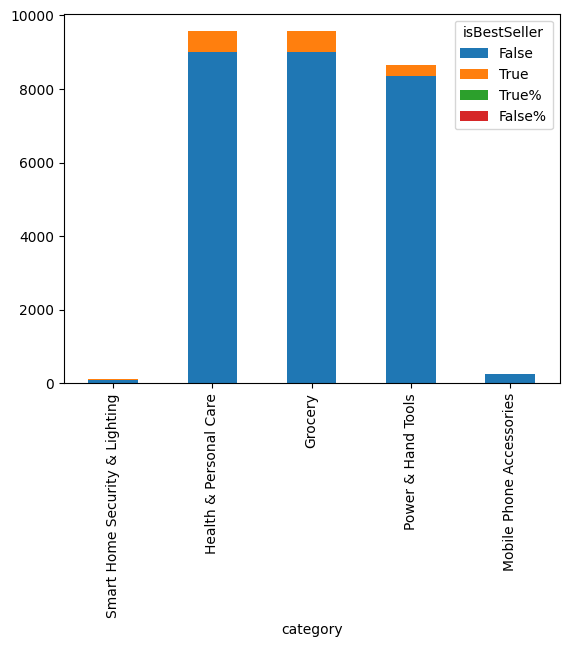

In [55]:
# 1.3 Visualization

crosstab_result = crosstab_result2.sort_values("True%", ascending = False).head(5)

crosstab_result.plot(kind='bar', stacked=True)
plt.show()

In [ ]:
# Part 2: Exploring Product Prices and Ratings Across Categories and Brands

# Objective: Investigate how different product categories influence product prices.

#    Preliminary Step: Remove outliers in product prices.

#    For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

#    Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

#    Violin Plots:
#        Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
#        Which product category tends to have the highest median price? Don't filter here by top categories.

#    Bar Charts:
#        Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
#        Which product category commands the highest average price? Don't filter here by top categories.

#    Box Plots:
#        Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
#        Which category tends to receive the highest median rating from customers? Don't filter here by top categories.


In [98]:
# 2.1 Remove outliers from the product price

def outlier_slayer(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify the outliers
    return  lower_bound, upper_bound



In [105]:
lower, upper = outlier_slayer(df["price"])

df_clean = df[(df["price"] >= lower) & (df["price"] <= upper)]


In [106]:
df_clean["price"].max()

np.float64(99.99)

In [108]:
df_clean_unqiue = df_clean["category"].value_counts()


In [109]:
df_clean_unqiue.head(20)

category
Sports & Outdoors                         694092
Beauty                                     19233
Bath & Body                                19050
Manicure & Pedicure Products               18904
Handmade Clothing, Shoes & Accessories     18811
Make-up                                    18718
Skin Care                                  18686
Hair Care                                  18625
Birthday Gifts                             18398
Handmade Gifts                             17948
Handmade Home Décor                        17675
Luggage and travel gear                    17557
Women                                      17476
Fragrances                                 17431
Handmade Kitchen & Dining                  17346
Handmade Artwork                           17269
Handmade Home & Kitchen Products           17175
Handmade Jewellery                         17135
Men                                        16596
Baby                                       14883
Name: count

In [112]:
top_categories = df_clean["category"].value_counts().nlargest(20).index
df_top = df_clean[df_clean['category'].isin(top_categories)]

C:\Users\yannik_sassmann\AppData\Local\Temp\ipykernel_31640\2969695002.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top, x="category", y="price", palette="coolwarm")


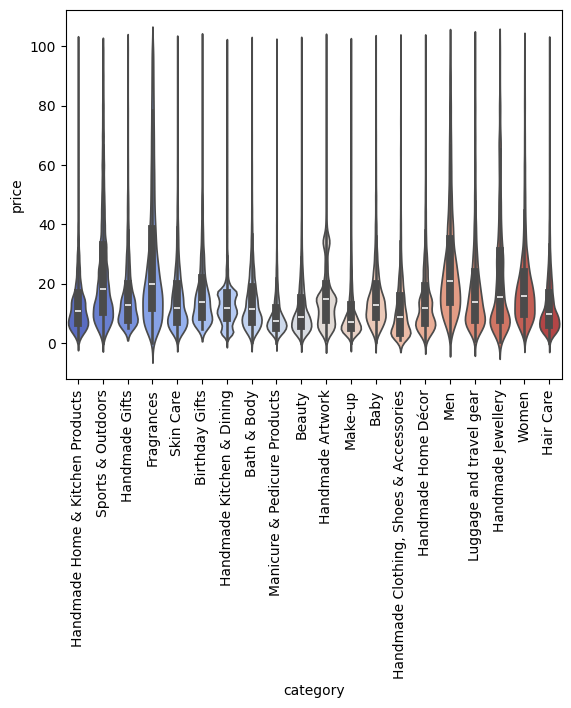

In [117]:
# 2.2 Violin Plots
sns.violinplot(data=df_top, x="category", y="price", palette="coolwarm")
plt.xticks(rotation=90)
plt.show()


In [ ]:
# Interpretation of results:

# The categories with the highest median are Fragrances, Men, Women and Handmade Jewellery.

In [114]:
# 2.2 Bar chart

top_categories_barchart = df_clean["category"].value_counts().nlargest(10).index
df_top_barchart = df_clean[df_clean['category'].isin(top_categories_barchart)]

In [ ]:
avg_price = df_top_barchart.groupby('category')['price'].mean().reset_index()

C:\Users\yannik_sassmann\AppData\Local\Temp\ipykernel_31640\2268148977.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_price, x='category', y='price', palette='coolwarm')


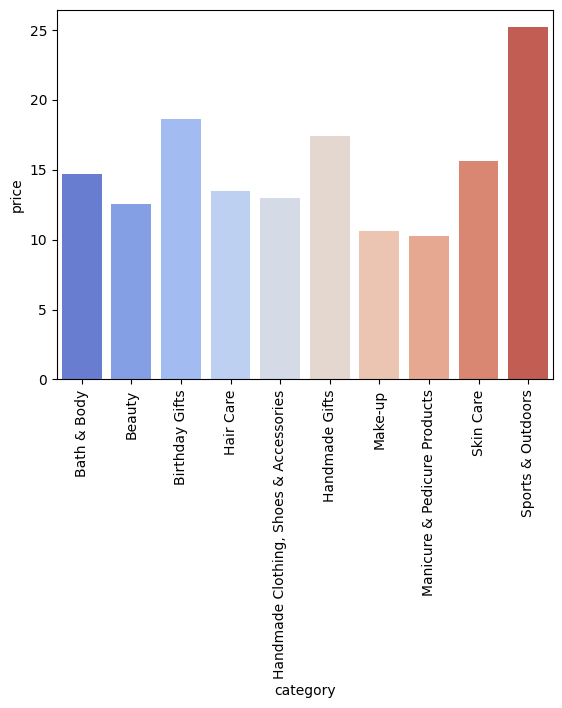

In [118]:
sns.barplot(data=avg_price, x='category', y='price', palette='coolwarm')
plt.xticks(rotation=90)
plt.show()

In [ ]:
# Interpretation of results:

# Category with the highest mean price is Sports & Outdoors

In [ ]:
# 2.3 Boxplots

In [126]:
df3 = df[df["stars"] != 0.0]

top_categories_boxplot = df3["category"].value_counts().nlargest(10).index
df_top_boxplot = df3[df3['category'].isin(top_categories_boxplot)]



In [127]:
median_rating = df_top_boxplot.groupby('category')['stars'].median().reset_index()

C:\Users\yannik_sassmann\AppData\Local\Temp\ipykernel_31640\3007304901.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=median_rating, x='category', y='stars', palette='coolwarm')


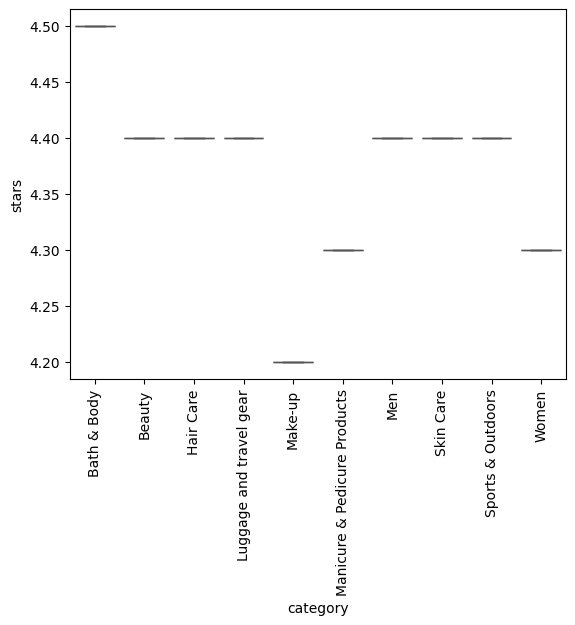

In [128]:
sns.boxplot(data=median_rating, x='category', y='stars', palette='coolwarm')
plt.xticks(rotation=90)
plt.show()

In [ ]:
# Interpretation of results:

# Bath & Body tends to receive the highest median rating from customers.


In [ ]:
# Part 3: Investigating the Interplay Between Product Prices and Ratings

# Objective: Analyze how product ratings (stars) correlate with product prices.

#    Correlation Coefficients:
#        Calculate the correlation coefficient between price and stars.
#        Is there a significant correlation between product price and its rating?

#    Visualizations:
#        Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
#        Use a correlation heatmap to visualize correlations between all numerical variables.
#        Examine if product prices typically follow a normal distribution using a QQ plot.

In [129]:
# 3.1 Correlation coefficients

round(float(df3["price"].corr(df["stars"], method="pearson")), 2)

-0.0

In [ ]:
# There is no significant colleration between price and stars

In [ ]:
# 3.2 Visualizations - Scatter plot & Heatmap

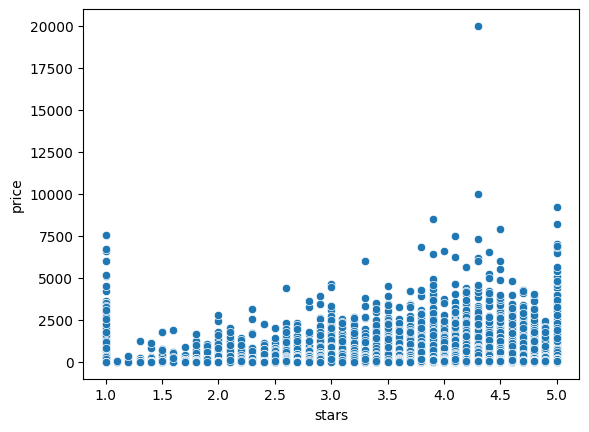

In [132]:
# Scatterplot

sns.scatterplot(x = df3["stars"], y= df3["price"])
plt.show()

In [133]:
# Heatmap

num = df3.select_dtypes(include="number")

In [134]:
num.corr()

,uid,stars,reviews,price,boughtInLastMonth
uid,1.000000,-0.008107,0.023818,-0.002096,0.017648
stars,-0.008107,1.000000,0.033712,-0.004912,0.038359
reviews,0.023818,0.033712,1.000000,-0.011032,0.096260
price,-0.002096,-0.004912,-0.011032,1.000000,-0.037266
boughtInLastMonth,0.017648,0.038359,0.096260,-0.037266,1.000000


In [135]:
correlation_matrix = num.corr()

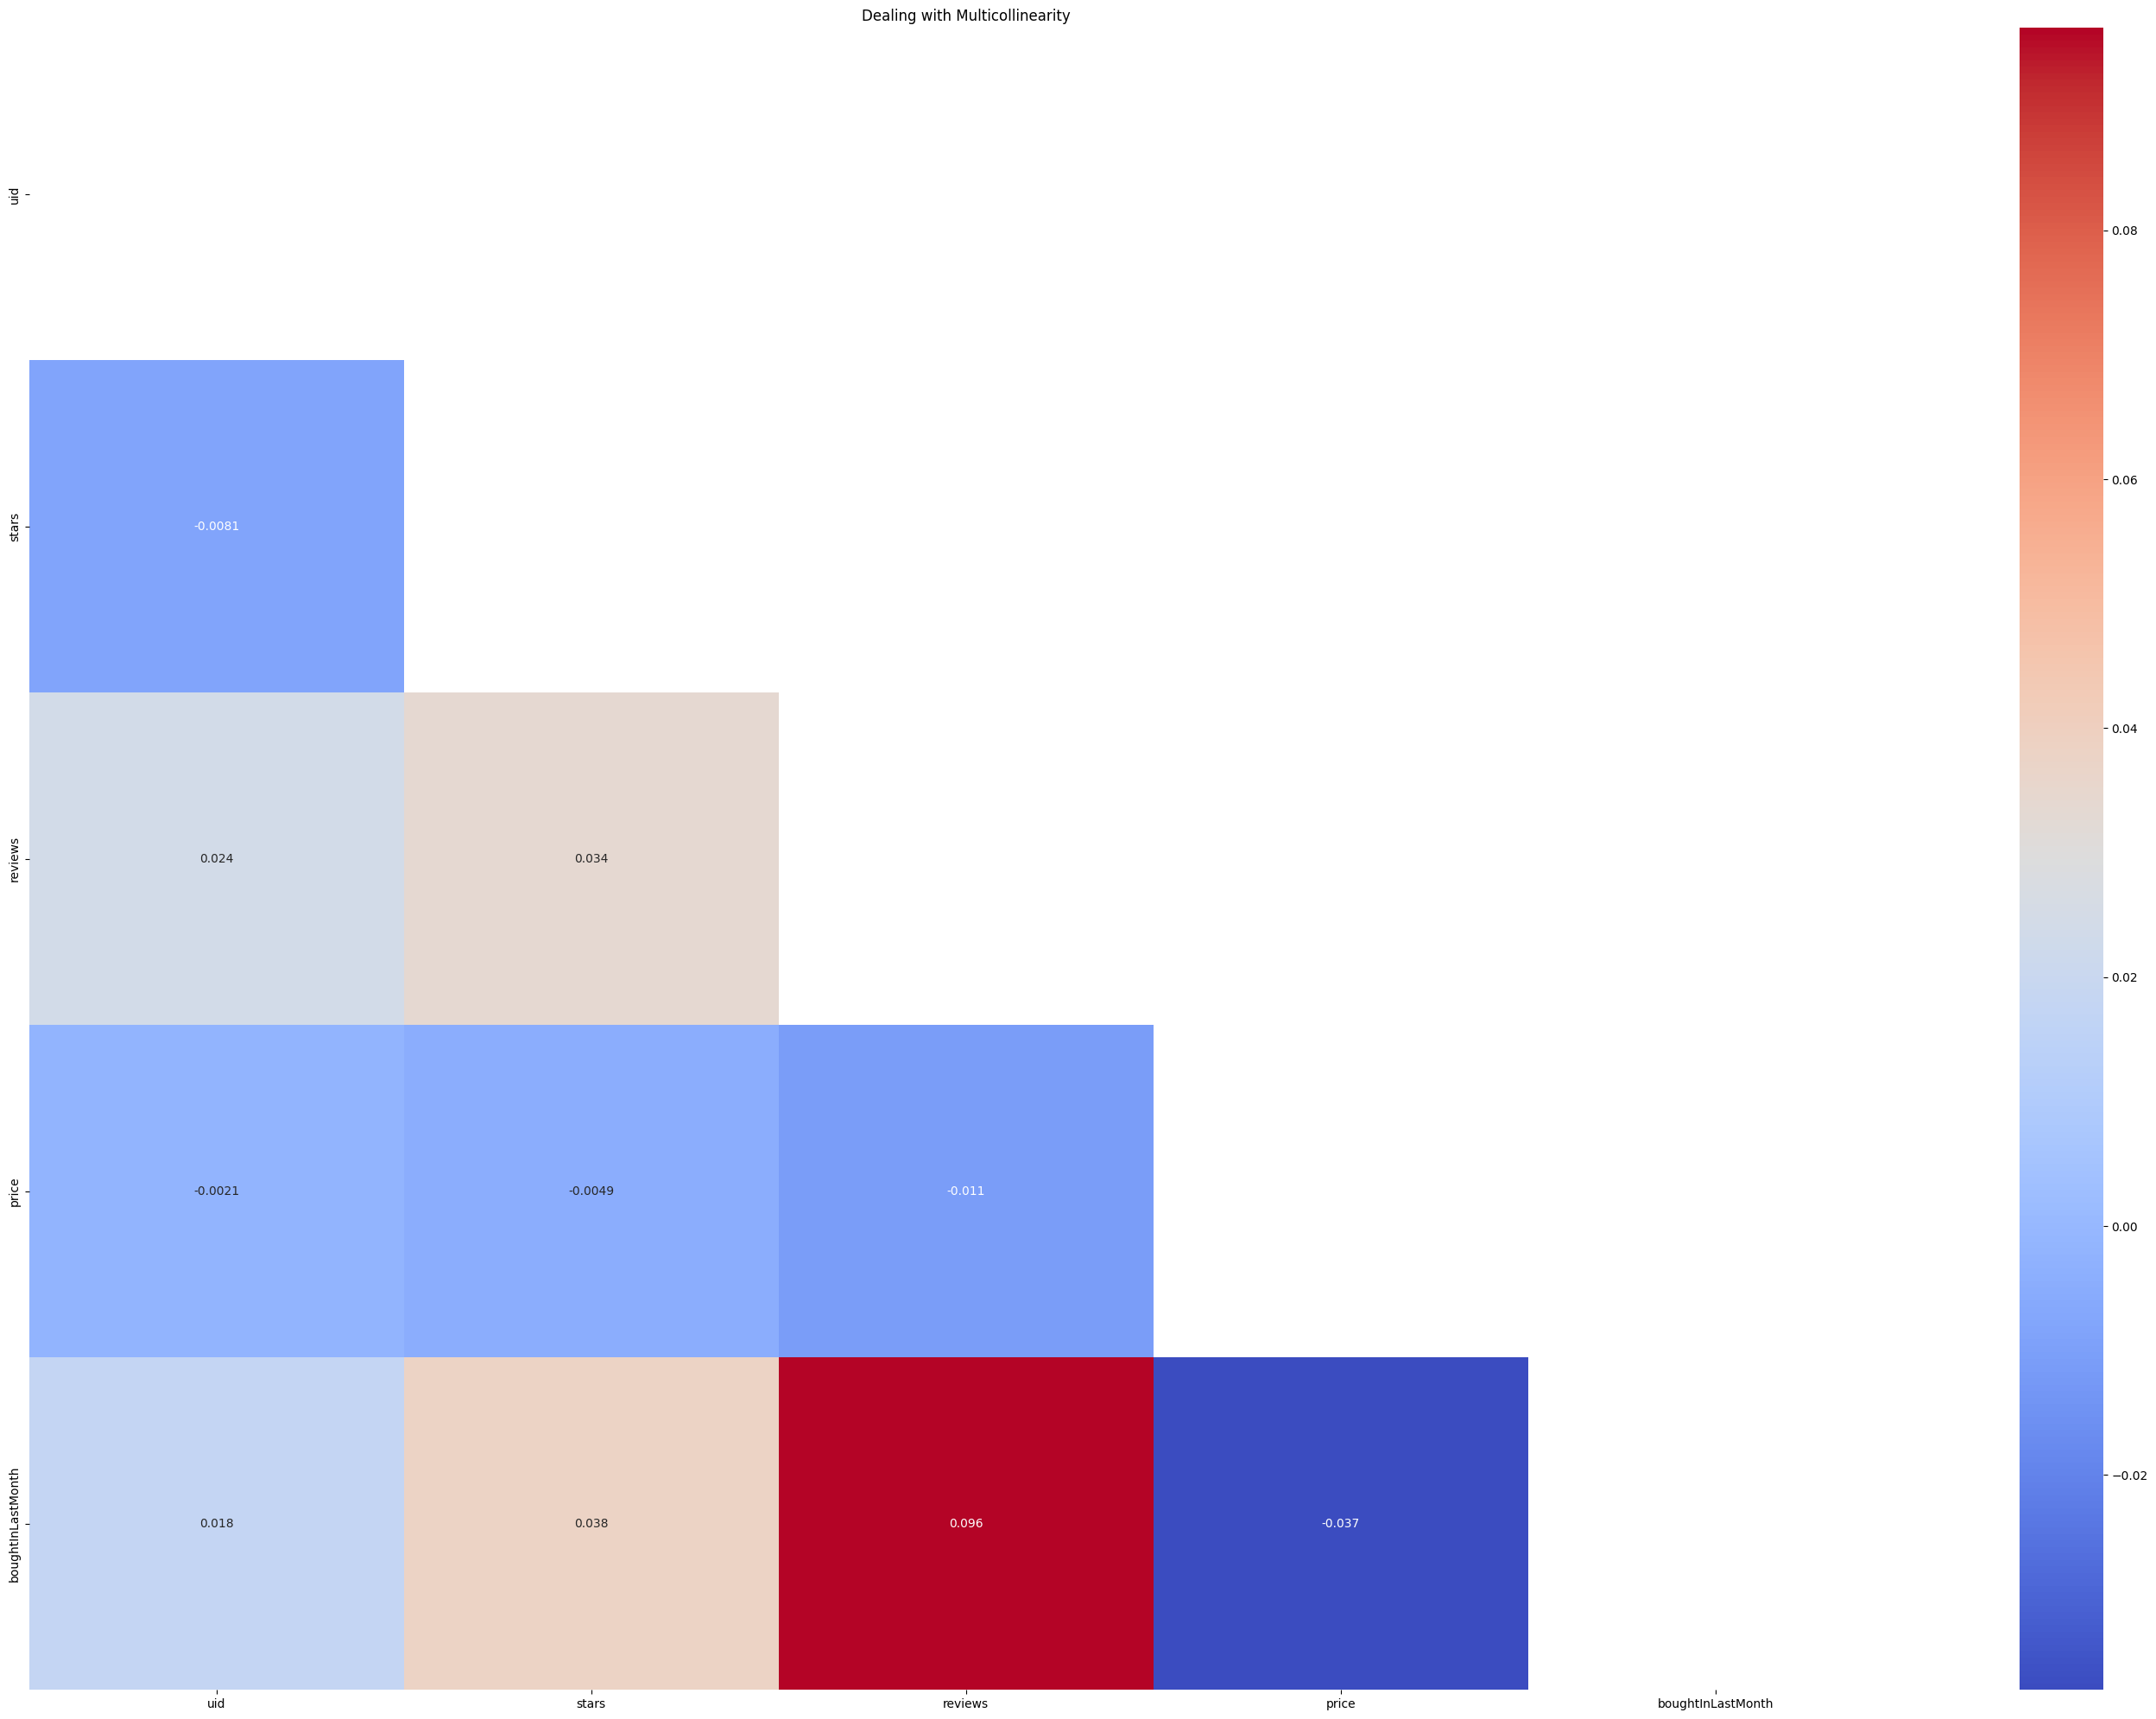

In [ ]:
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
plt.figure(figsize=(35, 25))
sns.heatmap(correlation_matrix, mask=mask, annot=True, cmap="coolwarm")

plt.title("Correlation Matrix")
plt.show()

In [137]:
# 3.3 QQ-Plot

import statsmodels.api as sm

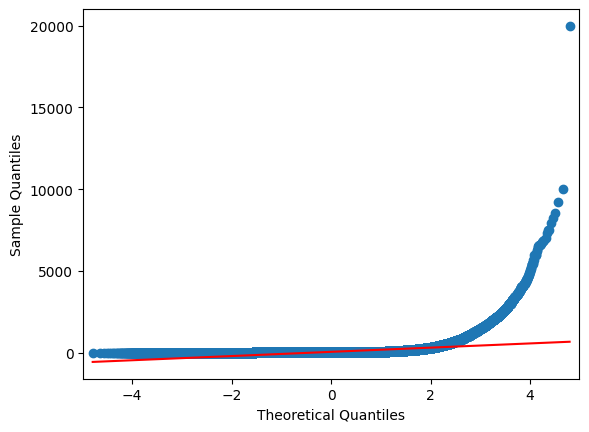

In [138]:
sm.qqplot(df3["price"], line='s');
plt.show()

In [ ]:
# Interpretation of results:

# The product prices doesnt follow a normal distribution.